fno_h32_m32x64_lr0.001_s42_128x256

The first training on 720 simulations for 50 epochs, best epoch is epoch  43 with train loss 0.01714 val loss 0.03169. Evaluating on 80 val simulations gives results:

target     all pts (mean±std)     surface (rel. to global std)

vx          43.6% ±  7.3%       126.3% ± 37.5%

vy          79.3% ± 12.8%        32.0% ± 25.2%

pressure    78.4% ± 17.2%        94.0% ± 138.5%

nu_t        64.7% ± 12.5%        55.1% ± 23.0%

In order to see if the model is underfitting or overfitting, evalute on the 20 of the training simaluations:

target     all pts (mean±std)     surface (rel. to global std)

vx          41.6% ±  5.4%       118.9% ± 37.1%

vy          77.8% ± 12.1%        29.0% ± 20.8%

pressure    73.9% ± 19.6%        51.4% ± 58.7%

nu_t        67.0% ± 12.0%        49.9% ± 15.7%


The results are close, it shows the model is underfitting, even though the loss curve looked fine. 

Hypothesis: grid space MSE weights every one of the 128X256 pixels equally, but most of them are smooth far-field flow. 

Therefore this notebook tests whether it's actually the case. We took one training simulation and plot the true and prediced grid (in the 128X256 grid space).

In [3]:
import sys
from afrans.config import REPO_ROOT
sys.path.append(str(REPO_ROOT/"scripts"))

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.spatial import Delaunay

In [4]:
from afrans.config import CACHE_DIR, CKPT_DIR, N_TARGETS, POS, TARGET_NAMES, FEATURES, TARGETS, SURFACE, GridConfig, TrainConfig
from afrans.engine import resolve_device
from afrans.interpolate import point_to_grid
from afrans.models.fno import build_fno
from afrans.normalise import Normaliser
from afrans.splits import load_split, simulation_names
from evaluate import load_full_sim

In [5]:
ckpt_path = CKPT_DIR / (TrainConfig().run_name(GridConfig()) + ".pt")
ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
train_cfg = TrainConfig(**ck["train_cfg"])
grid_cfg = GridConfig(**ck["grid_cfg"])
device = resolve_device(train_cfg)

model = build_fno(train_cfg)
model.load_state_dict(ck["model"])
model.to(device).eval()

norm = Normaliser()
norm.load(CACHE_DIR / "normaliser.npz")

print(f"{ckpt_path.name} epoch {ck['epoch']} val_loss {ck['val_loss']:.5f} device={device}")

fno_h32_m32x64_lr0.001_s42_128x256.pt epoch 43 val_loss 0.03169 device=mps


In [8]:
def predict_grid(model, normaliser, grid_cfg, device, sim):

    pos = sim[:, POS]
    tri = Delaunay(pos)
    gx, gy = grid_cfg.mesh()

    x_norm = normaliser.transform_feature(sim[:, FEATURES])
    y_norm = normaliser.transform_target(sim[:, TARGETS])

    x_grid = point_to_grid(x_norm, tri, gx, gy)
    y_true_grid = point_to_grid(y_norm, tri, gx, gy)

    x = torch.from_numpy(x_grid).unsqueeze(0).to(device)
    with torch.no_grad():
        y_pred_grid = model(x)[0].cpu().numpy()

    return y_true_grid, y_pred_grid

In [9]:
split = load_split(names=simulation_names("full"))
sim_name = split["train_names"][0]
sim = load_full_sim(sim_name)

y_true_grid, y_pred_grid = predict_grid(model, norm, grid_cfg, device, sim)

# airfoil location
surf_pos = sim[sim[:, SURFACE] > 0.5][:, POS]
pad = 0.3
x0, x1 = surf_pos[:, 0].min() - pad, surf_pos[:, 0].max() + pad
y0, y1 = surf_pos[:, 1].min() - pad, surf_pos[:, 1].max() + pad
print(f"{sim_name} zoom box: x[{x0:.2f}, {x1:.2f}] y[{y0:.2f}, {y1:.2f}]")

airFoil2D_SST_36.622_11.319_3.941_5.424_1.0_16.283 zoom box: x[-0.30, 1.30] y[-0.34, 0.43]


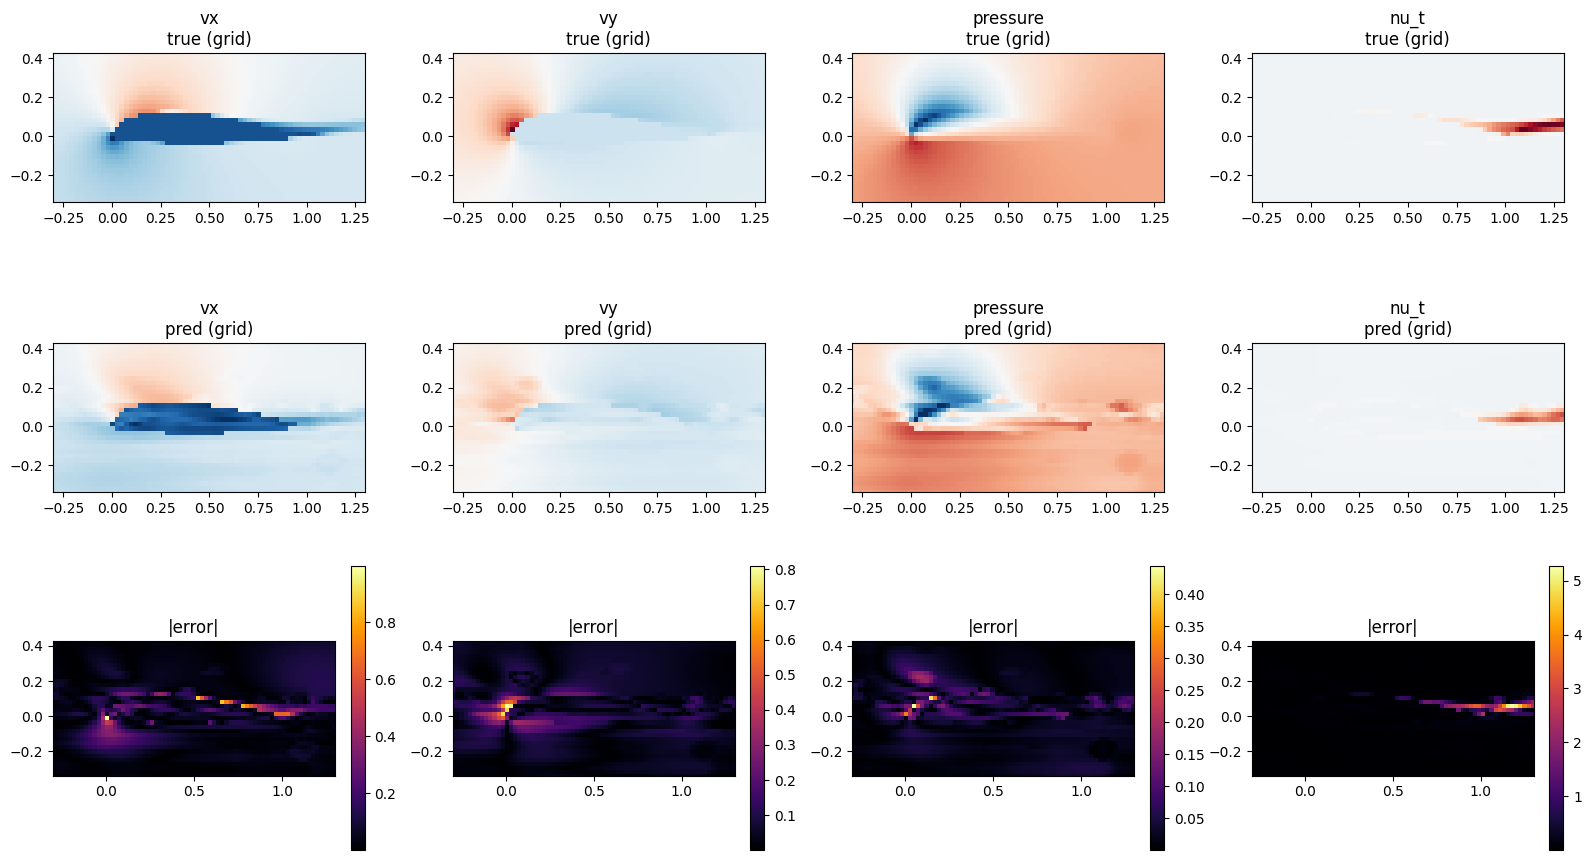

In [11]:
fig, axes = plt.subplots(3, N_TARGETS, figsize=(4*N_TARGETS, 9))

for j, name in enumerate(TARGET_NAMES):
    true_ch, pred_ch = y_true_grid[j], y_pred_grid[j]
    err_ch = np.abs(pred_ch - true_ch)
    vmax = np.abs(true_ch).max()

    axes[0, j].imshow(true_ch, extent=grid_cfg.extent, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[0, j].set_title(f"{name}\ntrue (grid)")
    axes[1, j].imshow(pred_ch, extent=grid_cfg.extent, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[1, j].set_title(f"{name}\npred (grid)")
    im = axes[2, j].imshow(err_ch, extent=grid_cfg.extent, origin="lower", cmap="inferno")
    axes[2, j].set_title("|error|")
    fig.colorbar(im, ax=axes[2, j], fraction=0.046)

    for ax in axes[:, j]:
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)

plt.tight_layout()
plt.show()

In [14]:
gx, gy = grid_cfg.mesh()
near_x = (gx[0] >= x0) & (gx[0] <= x1)
near_y = (gy[:, 0] >= y0) & (gy[:, 0] <= y1)
near_mask = np.outer(near_y, near_x)

print(f"airfoil bounding box {near_mask.mean():.2%} of the grid")
print(f"{'target':10s} {'MSE near airfoil':>18s} {'MSE far field':>15s} {'ratio':>8s}")
for j, name in enumerate(TARGET_NAMES):
    se = (y_pred_grid[j] - y_true_grid[j]) ** 2
    mse_near, mse_far = se[near_mask].mean(), se[~near_mask].mean()
    print(f"{name:10s} {mse_near:18.5f} {mse_far:15.5f} {mse_near/mse_far:8.1f}x")

airfoil bounding box 6.64% of the grid
target       MSE near airfoil   MSE far field    ratio
vx                    0.01230         0.00122     10.1x
vy                    0.00855         0.00074     11.6x
pressure              0.00179         0.00015     12.2x
nu_t                  0.15684         0.04825      3.3x


Most of the ratios of error near the airfoil and the error in far field are more than 10, means before map the grid back to point, the error is already large. This means the error is not because of the grid_to_point conversion (unavoidable floor), but because the training fail to fit especially at the surface.

Next steps: instead of uniform grid-space MSE, we should use a density-weighted loss, weighting grid cell by how many mesh points map into it.